---

MRI analysis 

---

In [1]:
# autoload
%load_ext autoreload
%autoreload 2
from pgl import pgl, pglDatabase, pglActions, pglFlywheel, pglAFNI, pglActionsMRI, pglActionsMNE, pglActionsFixes


---

Load behavioral data

---

In [ ]:
pgl.importSettings()

In [2]:
newSession = pglActions.loadSession.execute()
if newSession: 
    session = newSession
    session.print()

=================================== Session ====================================
  Source checkpoint : Not set
  Runs              : 10
  Filesystem        : file, local
  MEG/EEG data      : None
  MRI data          : None

---------------------------- Experiment and subject ----------------------------
  nsd-mini / sdbp_nsdmini_0002

------------------------------------ Run 1 -------------------------------------
Experiment: nsd-mini | Subject ID: sdbp_nsdmini_0002
Session: session_2026-11-13 | Run: run_12-28-39
2026-11-13T12:32:11.679832-08:00
Duration: 6 mins 16s
Number of volume triggers: 240
Median time between triggers: 1.510s
Mean ± std time between triggers: 1.569 ± 0.870336s
Suspected manual final trigger: trigger 240, gap=14.835s; excluded from missing-volume and timing-discrepancy counts.
Duration and interval statistics above still include this final trigger.
Possible missing volumes = 2
No interval timing discrepancies ≥100 ms detected, excluding any suspected manual fina

---

Fix missing volume triggers

---

In [3]:
fixVolumeTimes = pglActionsFixes.fixVolumeTimes()
newSession = fixVolumeTimes.execute(session=session)
if newSession: 
    session = newSession
    session.print()

(pglActionsFixes:_printPlan) Run 0: median volume time=1.510000 s; correction threshold=20 ms.
(pglActionsFixes:_printPlan)   Align isolated triggers to the midpoint of their original neighbors' median-TR predictions, only when those
predictions agree within 20 ms.
(pglActionsFixes:_printPlan)   Infer missing-trigger counts from median-TR multiples; interpolate their timestamps between retained anchors.
(pglActionsFixes:_printPlan)   Persistent timing shifts are not propagated or regularized.
(pglActionsFixes:_printPlan)   Remove a final trigger when its original gap exceeds 1.5 × median TR, unless the gap is within 100 ms of 2 × median
TR.
(pglActionsFixes:_printPlan)   Volumes: 240 → 241; insert=2, adjust=0, remove=1.
(pglActionsFixes:_printPlan)   Suspected manual ending: original final gap=14.834693 s (9.824 × median TR).
(pglActionsFixes:_printPlan)   Plan removes that final trigger without filling its gap. Explicit boundary/count edits apply afterward.
(pglMessages:warning) ❌ Run

In [ ]:
session.display()

In [ ]:
session.print()

---

Load data from flywheel

---

In [3]:
newSession = pglActions.loadFlywheel().execute(session=session, showScanCounts=False)
if newSession: 
    session = newSession
    session.print()

(pglFlywheel:__init__) Logged in as: Justin Gardner (jlg@stanford.edu)
(pglFlywheelProject:loadedSessions) Loading sessions: babybrains
(pglFlywheelSession:loadedScans) Loading scans: 2020-03-04 21:52 PST
(pglFlywheelProject:loadedSessions) Loading sessions: DigitalBrainsPilot
(pglFlywheelSession:loadedScans) Loading scans: 2026-02-11 14:10 UTC
(pglFlywheelSession:loadedScans) Loading scans: 2026-11-13 12:08 PST


             0% [   00:00<       ?] Preparing deferred Flywheel MRI scans

(loadFlywheel:_run) Attaching 48 deferred MRI scan(s) from Flywheel project '698b820dde4a9c690173d3e0', session '6af770dc92f0d6de8cd6296f',
to the existing session.
(loadFlywheel:_run) Preserving 10 behavioral run(s), existing labels, and other session contents. Scan-to-run alignment is not performed.
=================================== Session ====================================
  Source checkpoint : Not set
  Runs              : 10
  Filesystem        : file, local
  MEG/EEG data      : None
  MRI data          : 48 scans

---------------------------- Experiment and subject ----------------------------
  nsd-mini / sdbp_nsdmini_0002

------------------------------------ Run 1 -------------------------------------
Experiment: nsd-mini | Subject ID: sdbp_nsdmini_0002
Session: session_2026-11-13 | Run: run_12-28-39
2026-11-13T12:32:11.679832-08:00
Duration: 6 mins 16s
Number of volume triggers: 240
Median time between triggers: 1.510s
Mean ± std time between triggers: 1.569 ± 0.870336s

In [ ]:
session.mri.print(match='nsdmini')

Timeline alignment: first. Behavioral timestamps remain unchanged.
  Each matched MRI scan is shifted independently; inter-scan spacing may change.
  Volume correspondence is ordinal: first ↔ first, second ↔ second, etc.
  Scan 6 ↔ Run 2: 241 pairs; MRI shift=-1.550660 s.
    Align MRI first volume 1794602829.000000 UTC s → behavioral first trigger 1794602827.449340 UTC s.
    After alignment: RMS=763.260 ms; max absolute difference=1446.450 ms.
  Run 0: segment ticks from main task 0 ('nSD-mini').
    Segment 0: 120 recorded starts.
    Segment 1: 120 recorded starts.
  Run 1: segment ticks from main task 0 ('nSD-mini').
    Segment 0: 120 recorded starts.
    Segment 1: 120 recorded starts.


/var/folders/n2/4bqdpl1s6wd9x4l9ll4p03_m0000gq/T/ipykernel_49735/3205336309.py:7: RuntimeWarning: Scan 6 / Run 2: 242 MRI volumes versus 241 behavioral triggers. Scatter and bestMatch use the first 241 ordinal pairs. Internal missing/extra triggers can invalidate subsequent pairings.
  timeline = pglScanTimelinePlot(


  Run 2: segment ticks from main task 0 ('nSD-mini').
    Segment 0: 120 recorded starts.
    Segment 1: 120 recorded starts.
  Run 3: segment ticks from main task 0 ('nSD-mini').
    Segment 0: 120 recorded starts.
    Segment 1: 120 recorded starts.
  Run 4: segment ticks from main task 0 ('nSD-mini').
    Segment 0: 120 recorded starts.
    Segment 1: 120 recorded starts.
  Run 5: segment ticks from main task 0 ('nSD-mini').
    Segment 0: 120 recorded starts.
    Segment 1: 120 recorded starts.
  Run 6: segment ticks from main task 0 ('nSD-mini').
    Segment 0: 120 recorded starts.
    Segment 1: 120 recorded starts.
  Run 7: segment ticks from main task 0 ('nSD-mini').
    Segment 0: 120 recorded starts.
    Segment 1: 120 recorded starts.
  Run 8: segment ticks from main task 0 ('nSD-mini').
    Segment 0: 120 recorded starts.
    Segment 1: 120 recorded starts.
  Run 9: segment ticks from main task 0 ('nSD-mini').
    Segment 0: 120 recorded starts.
    Segment 1: 120 recorded 

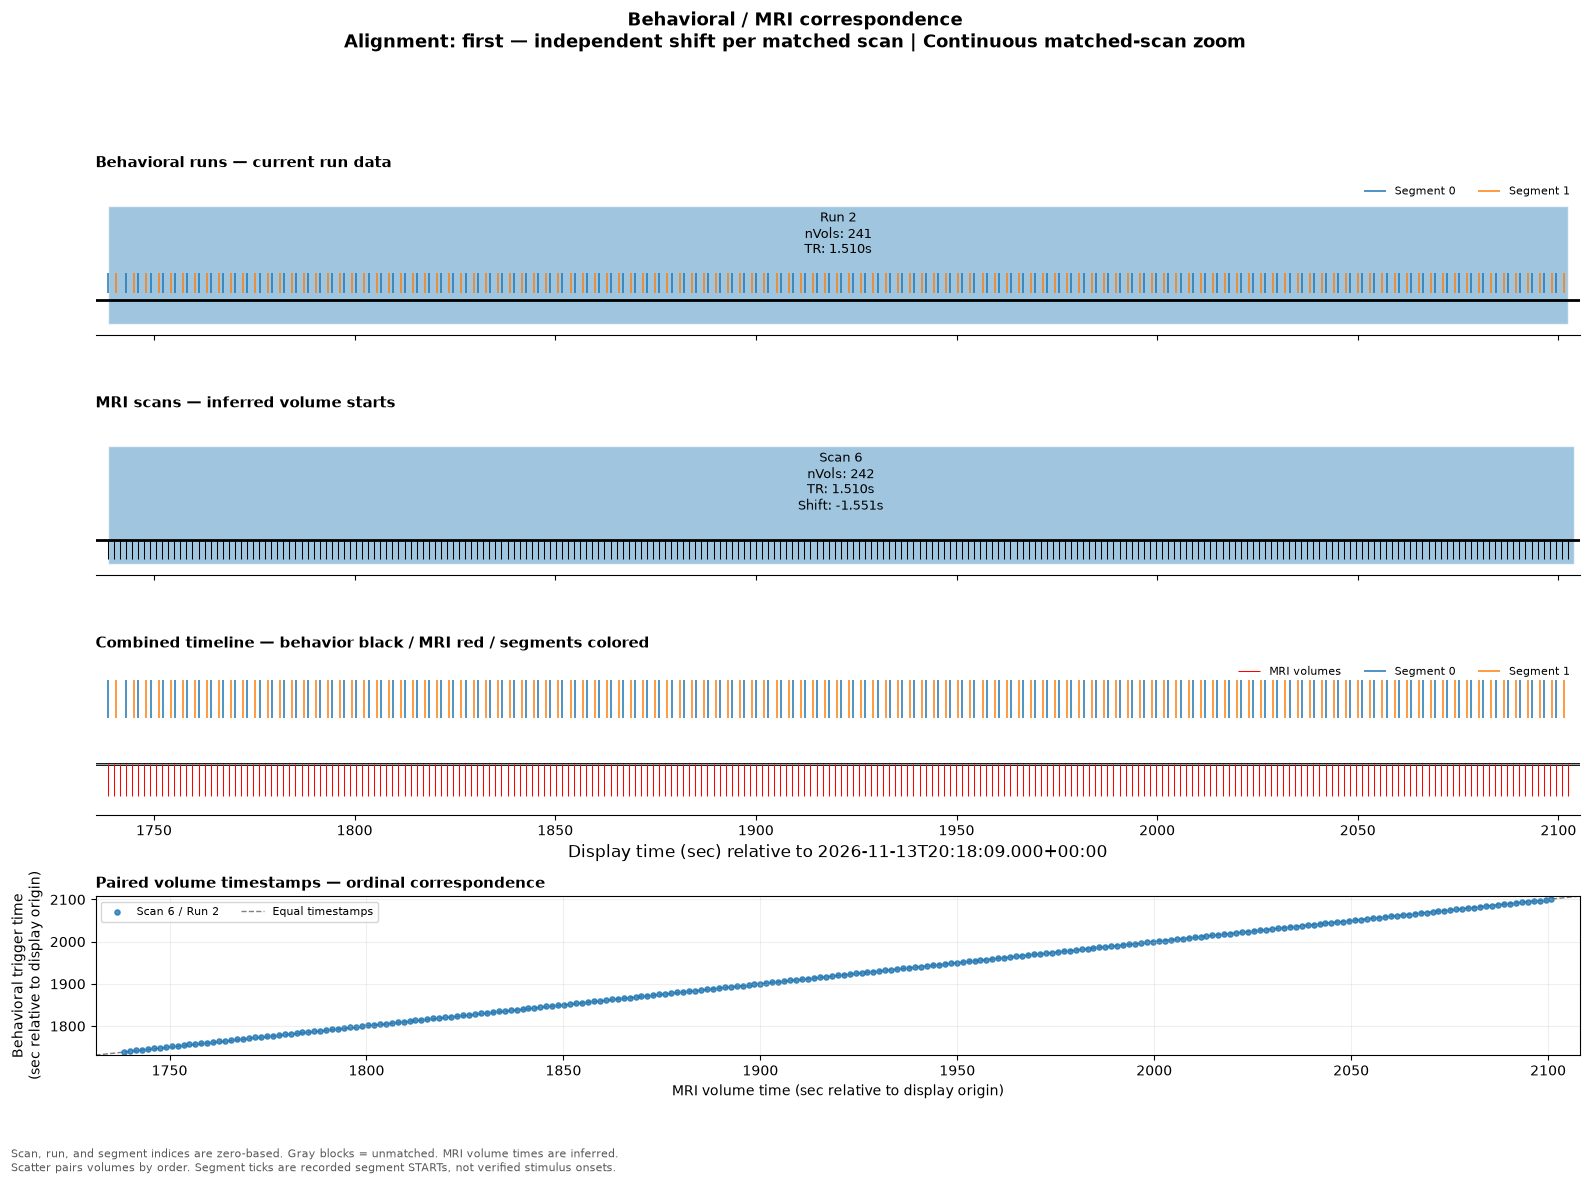

In [ ]:
from pgl.pglPlots import pglScanTimelinePlot

# Zero-based (scanIndex, runIndex) pairs.
# Scan 0, the T1, remains unmatched.
proposedMatch = [(4, 0), (5, 1), (6, 2), (10, 3), (11, 4), (12, 5), (17,6), (21, 7), (22, 8), (23, 9)]
proposedMatch = (6, 2)
timeline = pglScanTimelinePlot(
    pglRuns=session.runs,
    pglScans=session.mri.scans,
    proposedMatch=proposedMatch,
    alignmentMode='first',
    volumeMarkerStyle='tick',
    showTrialSegments=True,
    showBehaviorVolumes=True,
    zoom=True,
)

#print(f"MRI shift: {timeline.getAlignmentOffset():+.3f} sec")
timeline.show()

In [ ]:
for scanIndex, runIndex in proposedMatch:
    scan = session.mri.scans[scanIndex]
    summary = scan.getScanSummary(readHeaders=True)

    print(f"\nScan {scanIndex}: {scan.name} → Run {runIndex}")
    print(f"  scanDims:  {summary.get('scanDims')!r}")
    print(f"  trSeconds: {summary.get('trSeconds')!r}")

In [ ]:
session.mri.print(match='nsdmini')

---

AFNI: check availability and optional install

---

In [ ]:
afni = pglAFNI(directory="~/proj/afni/abin")
available = afni.checkAvailable("3dvolreg")

In [ ]:
afni = pglAFNI()
afni.install()

In [ ]:
pglActions.help()
